# **A. The $\beta$-method for a scalar IVP**

In [ ]:
# import all the packages here

import numpy as np
import matplotlib.pyplot as plt

import warnings


In [ ]:
# Performs integration for the linear IVP given by
#           d/dt u = lambda * u + g(t), u(t_0) = u_0
# using the beta-method
#
# INPUT
# lambda        constant defining the rhs
# g             function defining time-depdendent part of rhs
# tRange        the time interval [t_0, T] of integration
# u0            initial solution at t = tRange(1) (N x 1 array)
# beta          defines the method
# h             the step-size
#
# OUTPUT
# tArray        array containing the time points
# solArray      array containing the solution at each time point
#               (the ith row equals the solution at time tArray(i))

def LinearBetaMethod(Lambda, g, tRange, u0, beta, h):

    tArray = []
    solArray = []

    solArray.append(u0)


    t_n = np.linspace(tRange[0], tRange[1], int((tRange[1]-tRange[0])/h) + 1)

    # main loop: separate the cases for explicit and implicit Euler methods

    if beta == 0:
      for i in range(1, len(t_n)):

        uNew = ((h * (1 - beta) * Lambda) + 1) * solArray[i - 1] + h * g(t_n[i - 1])
        solArray.append(uNew)
    elif beta <= 1:
      for i in range(1, len(t_n)):
        t_nBeta = t_n[i - 1] + beta * h
        u_nPlusOne = (1 / (1 - h * Lambda * beta)) * (solArray[i - 1]*(1 + h * Lambda * (1 - beta)) + h * g(t_nBeta))

        solArray.append(u_nPlusOne)
    else:
      print('non valid value for Beta')

    return t_n, solArray




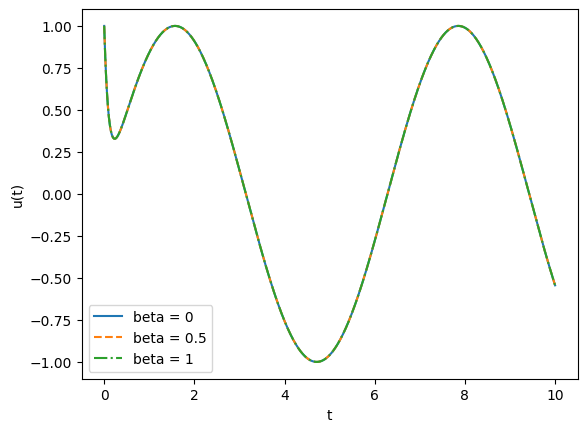

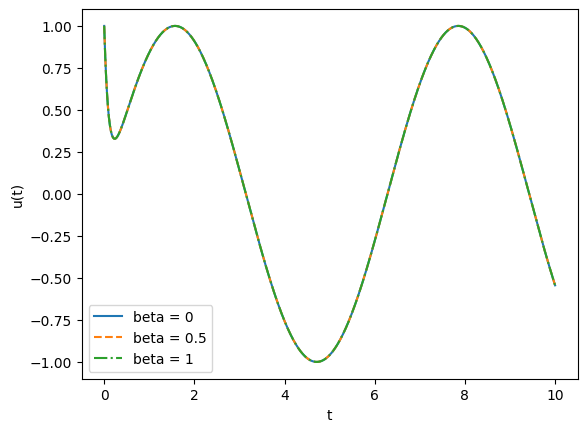

In [ ]:
# Test of the linear solver

tRange = np.array([0,10])
y0 = 1.
Lambda = -10
h = 0.0001
g = lambda x: np.cos(x) - Lambda * np.sin(x)

linestyle = ['-','--','-.']

for i in [0, 0.5, 1]:
  tArray, solArray = LinearBetaMethod(Lambda, g, tRange, y0, i, h)

  plt.plot(tArray, solArray, label='beta = ' + str(i), linestyle = linestyle[int(2*i)])
  plt.xlabel('t')
  plt.ylabel('u(t)')
  plt.legend()
plt.show()

Lambda = -10

for i in [0, 0.5, 1]:
  tArray, solArray = LinearBetaMethod(Lambda, g, tRange, y0, i, h)

  plt.plot(tArray, solArray, label='beta = ' + str(i), linestyle = linestyle[int(2*i)])
  plt.xlabel('t')
  plt.ylabel('u(t)')
  plt.legend()
plt.show()




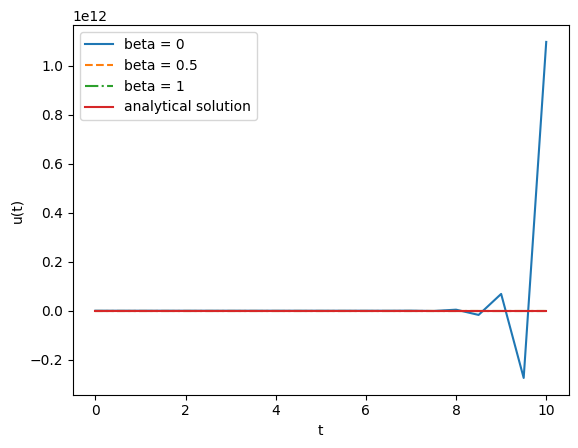

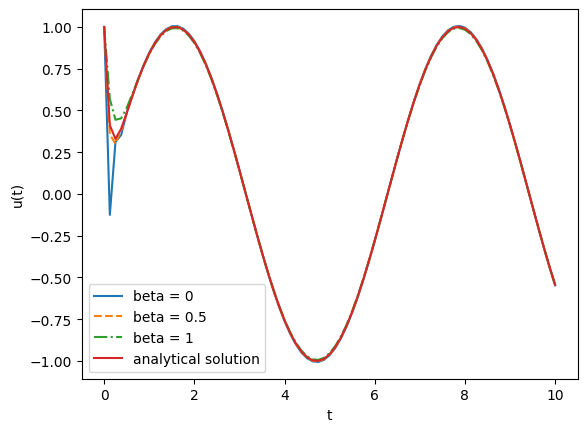

In [ ]:
## Discussion question (a)-(b)

# new inputs for LinearBetaMethod and the analytical solution
h = 0.5
Lambda = -10
tRange = np.array([0,10])
y0 = 1.
g = lambda x: np.cos(x) - Lambda * np.sin(x)
analytical_solution = lambda x: np.exp(Lambda * x)  + np.sin(x)



for i in [0, 0.5, 1]:  # for each value of h create a figure containing the analytical solution and 3 numerical ones
  tArray, solArray = LinearBetaMethod(Lambda, g, tRange, y0, i, h)


  plt.plot(tArray, solArray, label='beta = ' + str(i), linestyle = linestyle[int(2*i)])


analytical_solArray = analytical_solution(tArray)
plt.plot(tArray, analytical_solArray, label='analytical solution')
plt.xlabel('t')
plt.ylabel('u(t)')
plt.legend()
plt.show()


h = 0.125

for i in [0, 0.5, 1]:
  tArray, solArray = LinearBetaMethod(Lambda, g, tRange, y0, i, h)


  plt.plot(tArray, solArray, label='beta = ' + str(i), linestyle = linestyle[int(2*i)])


analytical_solArray = analytical_solution(tArray)
plt.plot(tArray, analytical_solArray, label='analytical solution')
plt.xlabel('t')
plt.ylabel('u(t)')
plt.legend()
plt.show()


# **B. Accuracy of the $\beta$-method**

0.5
0.6
0.6666666666666666


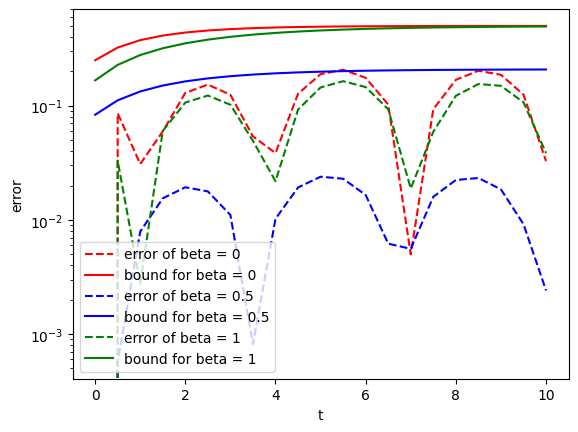

In [ ]:
from re import L
## Discussion question B.1

h = 0.5
Lambda = -1
tRange = np.array([0,10])
y0 = 1.
g = lambda x: np.cos(x) - Lambda * np.sin(x)
analytical_solution = lambda x: np.exp(Lambda * x)  + np.sin(x)
analytical_solArray = analytical_solution(tArray)



for i in [0, 0.5, 1]:
  if i == 0.5:
    Tau = h ** 3 * (1 + abs(Lambda) ** 3) / 24 + (3/8) * h ** 3 * abs(Lambda) * (1 + abs(Lambda) ** 2)
  else:
    Tau = h ** 2 * (1 + abs(Lambda) ** 2) / 2

  tArray, solArray = LinearBetaMethod(Lambda, g, tRange, y0, i, h)

  # define the amplification factor A as a function

  A = lambda h, Lambda, beta: (1 + (1- i) * h * Lambda) / (1 - i * h * Lambda)
  RHS = (Tau / abs(1 - i * h * Lambda)) * (1 - A(h, Lambda, i) ** (tArray + 1)) / (1 - A(h, Lambda, i))

  # plotting error and RHS using semilogy
  color = ['r', 'b', 'g']

  error = np.abs(solArray - analytical_solArray)
  print(A(h, Lambda, i))
  plt.semilogy(tArray, error, label = f'error of beta = {i}', linestyle = linestyle[1], color = color[int(2*i)])
  plt.semilogy(tArray, RHS, label = f'bound for beta = {i}',color  = color[int(2*i)] )


plt.xlabel('t')
plt.ylabel('error')
plt.legend()
plt.show()






slope for beta = 0 is [0.02442091 0.04854003 0.06598476 0.07050307 0.07217045 0.07289112
 0.07306282]
slope for beta = 0.5 is [0.00910947 0.00775802 0.00490448 0.00256578 0.00129666 0.00065004
 0.00048779]
slope for beta = 1 is [0.0809533  0.07927025 0.07715927 0.0756498  0.07469099 0.07414485
 0.07400214]


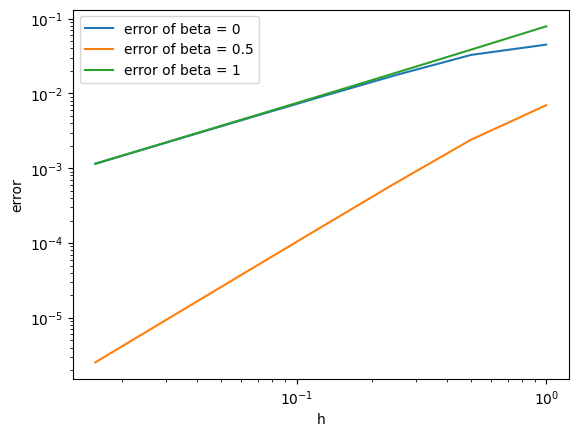

In [ ]:
## Discussion question c.)

# the idea is completely analogous to the previous part

Lambda = -1
tRange = np.array([0,10])
y0 = 1.
g = lambda x: np.cos(x) - Lambda * np.sin(x)
analytical_solution = lambda x: np.exp(Lambda * x)  + np.sin(x)
analytical_solArray = analytical_solution(tArray)



for i in [0, 0.5, 1]:
    ErrorList = []
    hList = []
    for l in range(0, 7):  # set up the corrct values for h
      h = 2 ** (-l)
      hList.append(h)
      tArray, solArray = LinearBetaMethod(Lambda, g, tRange, y0, i, h)
      error = np.abs(solArray[-1] - analytical_solArray[-1])
      ErrorList.append(error)
    print(f'slope for beta = {i} is {np.gradient(ErrorList , hList)}')

    plt.loglog(hList, ErrorList, label = f'error of beta = {i}')

plt.xlabel('h')
plt.ylabel('error')
plt.legend()
plt.show()


In [ ]:
# d.)

# Stability: stable if A(Lambda * h) < 1 for all h >0, beta = 0 guarantees only conditional stability (doesnt work for large h), beta = 1/2 and beta = 1 unconditional stability guranateed




## **C. The $\beta$-method for a system of IVP**

In [ ]:

def fpIterator(phi, x0, maxit, tol=1e-8):

    # initialize your output variables here (x, errEst, xHist)
    x = x0
    errEst = []
    xHist = []

    # loop (at most maxit iterations) to find the root; possible strategies
    for i in range(maxit):
    # check for convergence, i.e. check if the error at the current iteration
    # reached the tolerance
        xHist.append(x)
        if np.linalg.norm(phi(x) - x) <= tol:
            success = True
            break   # if yes >>> break
        else:     # if no >>> update the previous iteration x and iterate again
            success = False
            errEst.append(np.linalg.norm(phi(x) - x))
            x = phi(x)   # inside the loop you will have to compute the new guess for the root and

    return x, success, errEst, xHist

def newton(f, df, x0, tol=1e-8, maxit = 20):
    x = x0

    if type(x) == float:


      phi = lambda x: x - f(x) / df(x)

      x, success, errEst, xHist = fpIterator(phi, x, tol = 1e-30, maxit = 20)
    else:

      uNew = lambda x: x - np.matmul(np.linalg.inv(df(x)), f(x))

      x, success, errEst, xHist = fpIterator(uNew, x, maxit, tol = 1e-8)


    return x, success, errEst, xHist

def newtonNonlienar(F, J, x0, maxit, tol=1e-8):
    x = x0

    uNew = lambda x: x - np.matmul(np.linalg.inv(J(x)), F(x))

    x, success, errEst, xHist = fpIterator(uNew, x, maxit, tol = 1e-8)

    return x, success, errEst, xHist




In [ ]:
# Performs integration for the system of IVPs given by
#           d/dt u = f(t, u), u(t_0) = u_0
# using the beta-method
# INPUT
# f             the right-hand side function, the output should be a
#               N x 1 array where N is the number of unknowns
# tRange        the time interval [t_0, T] of integration
# u0            initial solution at t = tRange(1) (N x 1 array)
# df            a function that evaluates the Jacobian matrix of f
# beta          defines the method
# h             the step-size
#
# OUTPUT
# tArray        array containing the time points
# solArray      array containing the solution at each time point
#               (the ith row equals the solution at time tArray(i))

def BetaMethod(f, tRange, u0, df, beta, h):


    # initialize your output as for the linear version and set up th newton()
    # inputs

    tArray = [tRange[0]]
    solArray = []
    solArray.append(u0)


    t_n = np.linspace(tRange[0], tRange[1], int((tRange[1]-tRange[0])/h) + 1)

    # main loop: separate the cases for explicit and implicit Euler methods

    if np.isscalar(u0):
        N = 1
    else:
        N = len(u0)

    Identity = np.identity(N)   # you will need a predefined identity matrix for the implicit case



    for i in range(1, len(t_n)):


        if beta == 0:   #explicit method
          u = solArray[i - 1] + h * f(t_n[i - 1], solArray[i - 1])
          solArray.append(u)
          tArray.append(t_n[i])

        elif beta == 1:  #implicid method
          Residual = lambda uNew: uNew - solArray[i - 1] - h * f(t_n[i], uNew)
          Jacobian = lambda uNew: Identity - h * df(t_n[i], uNew)

          u, success, errEst, xHist = newton(Residual, Jacobian, solArray[i - 1], maxit=50, tol=1e-12)
          if not success:
            warnings.warn('newton doesnt converge')
            break

          solArray.append(u)
          tArray.append(t_n[i])

        else:   # implicit method general
          # for the implicit method you will need to define F, DF and X0 for newton()
          Residual = lambda uNew: uNew - solArray[i - 1] - h * f(t_n[i - 1] + h * beta, (1 - beta) * solArray[i - 1] + beta * uNew)
          Jacobian = lambda uNew: Identity - h * beta * df(t_n[i - 1] + h * beta, (1 - beta) * solArray[i - 1] + beta * uNew)

          u, success, errEst, xHist = newton(Residual, Jacobian, solArray[i - 1], maxit=50, tol=1e-12)
          solArray.append(u)
          tArray.append(t_n[i])



    return tArray, solArray

    # Linear test



h = 0.5
Lambda = -1
tRange = np.array([0,10])
y0 = 1.
g = lambda x: np.cos(x) + np.sin(x)
f  = lambda y, t: Lambda * y + g(t)
df = lambda t, y: Lambda



tArray, solArray = BetaMethod(f, tRange, y0, df, beta = 1, h = 0.5)




/tmp/ipykernel_338/3122785843.py:56: UserWarning: newton doesnt converge
  warnings.warn('newton doesnt converge')


In [ ]:
# INPUT
# x             position of dynamic body
# G             gravitational constant
# M             mass of attracting body
#
# OUTPUT
# g             gravitational acceleration


def gravAccF(x, G, M):


    g = - (((G * M)) / ((np.linalg.norm(x)) ** 3)) * x  # use the formula in equation (9)



    return g

In [ ]:
# INPUT
# x             position of dynamic body
# G             gravitational constant
# M             mass of attracting body
#
# OUTPUT
# jacG          Jacobian of gravitational acceleration w.r.t. position x

def gravAccJac(x, G, M):
    r = np.linalg.norm(x)
    jacG = (-G * M / r**3) * np.identity(len(x)) + (3 * G * M / r**5) * np.outer(x, x)
    return jacG


[-39.4784176  -0.         -0.       ]


/tmp/ipykernel_338/3122785843.py:56: UserWarning: newton doesnt converge
  warnings.warn('newton doesnt converge')


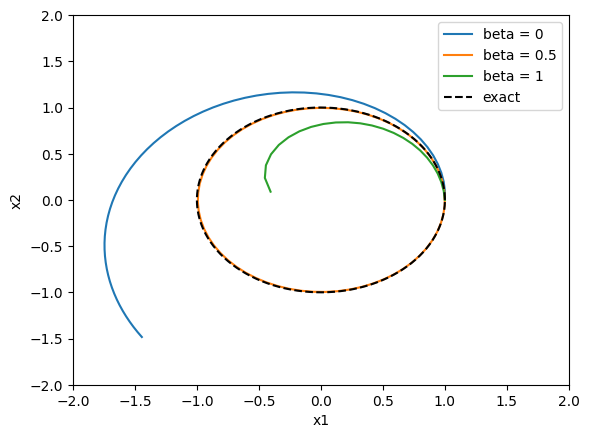

In [ ]:

## Discussion question e.)

# set up all the parameters for the 2 body problem

R = 1
M = 1
G = 4 * (np.pi ** 2)
omega = np.sqrt(G * M / (R ** 3))
T = (2*np.pi) / omega
h = (2 ** (-6)) * T

# x_exact = R * np.array[ np.cos(t * omega), np.sin(t * omega), 0]


#define all the inputs for BetaMethod() and the exact solution function

x0 = R * np.array([1, 0, 0])
tRange = np.array([0, T])
v0 = omega * R * np.array([0, 1, 0])

y0 = np.concatenate([v0, x0])

def f(t, y):
    v = y[:3]
    x = y[3:]
    return np.concatenate([gravAccF(x, G, M), v])

def df(t, y):
    v = y[:3]
    x = y[3:]
    return np.block([[np.zeros((3,3)), gravAccJac(x, G, M)],[np.identity(3), np.zeros((3,3))]])

print(gravAccF(np.array([1,0,0]), G, M))

tExact = np.linspace(0, T, 500)

x1_exact = R * np.cos(omega * tExact)
x2_exact = R * np.sin(omega * tExact)

for i in [0, 0.5, 1]:  #  solve the system using BetaMethod() and plot (x_1(t), x_2(t)) for 3 values of h
  tArray, solArray = BetaMethod(f, tRange, y0, df, beta = i, h = h)
  solArray = np.array(solArray)
  plt.plot(solArray[:, 3], solArray[:, 4], label = f'beta = {i}')

plt.plot(x1_exact, x2_exact, 'k--', label='exact')
plt.xlabel('x1')
plt.ylabel('x2')
plt.xlim(-2, 2)
plt.ylim(-2, 2)
plt.legend()
plt.show()




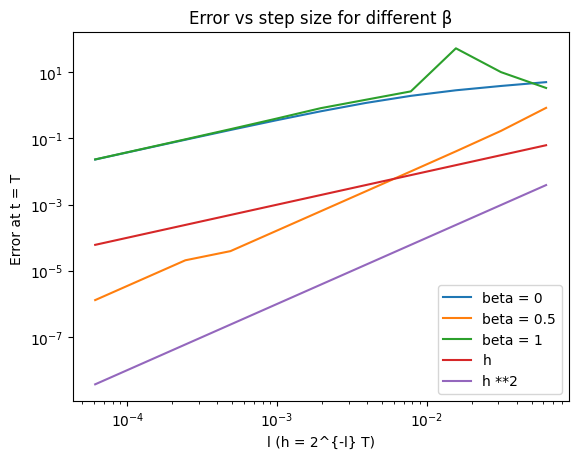

In [ ]:
## Discussion question C.2

# set up the inputs of BetaMethod and initialize the error variable
# solve the system using different values of beta and h and store the error

for i in [0, 0.5, 1]:
  Solutions = []
  ErrorList = []
  lValues = list(range(4, 15))
  hList = []
  for l in lValues:
    h = (2 ** (-l)) * T
    hList.append(h)
    tArray, solArray = BetaMethod(f, tRange, y0, df, beta = i, h = h)
    solArray = np.array(solArray)
    Solutions.append(solArray)
    error = np.linalg.norm(solArray[-1, 3:] - np.array([x1_exact[-1], x2_exact[-1], 0]))
    ErrorList.append(error)

  plt.loglog(hList, ErrorList, label = f'beta = {i}')

plt.loglog(hList, hList, label  = 'h')
plt.loglog(hList, np.array(hList) ** 2, label = 'h **2')
plt.yscale('log')
plt.xlabel('l (h = 2^{-l} T)')
plt.ylabel('Error at t = T ')
plt.legend()
plt.title('Error vs step size for different β')
plt.show()



